In [1]:
import pandas as pd

In [2]:
food = pd.read_csv("food_orders_new_delhi (1).csv")
food.head()

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks
0,1,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,1914,0,Credit Card,5% on App,150,47,0
1,2,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,986,40,Digital Wallet,10%,198,23,0
2,3,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,937,30,Cash on Delivery,15% New User,195,45,0
3,4,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,1463,50,Cash on Delivery,NaN,146,27,0
4,5,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,1992,30,Cash on Delivery,50 off Promo,130,50,0


In [3]:
food.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 12 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   Order ID                1000 non-null   int64
 1   Customer ID             1000 non-null   str  
 2   Restaurant ID           1000 non-null   str  
 3   Order Date and Time     1000 non-null   str  
 4   Delivery Date and Time  1000 non-null   str  
 5   Order Value             1000 non-null   int64
 6   Delivery Fee            1000 non-null   int64
 7   Payment Method          1000 non-null   str  
 8   Discounts and Offers    815 non-null    str  
 9   Commission Fee          1000 non-null   int64
 10  Payment Processing Fee  1000 non-null   int64
 11  Refunds/Chargebacks     1000 non-null   int64
dtypes: int64(6), str(6)
memory usage: 93.9 KB


In [4]:
food.describe(include="all")

,Order ID,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Order Value,Delivery Fee,Payment Method,Discounts and Offers,Commission Fee,Payment Processing Fee,Refunds/Chargebacks
count,1000.000000,1000,1000,1000,1000,1000.000000,1000.000000,1000,815,1000.00000,1000.000000,1000.000000
unique,NaN,947,621,1000,1000,NaN,NaN,3,4,NaN,NaN,NaN
top,NaN,C7949,R2317,2024-02-01 01:11:52,2024-02-01 02:39:52,NaN,NaN,Cash on Delivery,10%,NaN,NaN,NaN
freq,NaN,3,6,1,1,NaN,NaN,357,233,NaN,NaN,NaN
mean,500.500000,NaN,NaN,NaN,NaN,1053.969000,28.620000,NaN,NaN,126.99000,29.832000,28.300000
std,288.819436,NaN,NaN,NaN,NaN,530.975339,16.958278,NaN,NaN,43.06405,11.627165,49.614228
min,1.000000,NaN,NaN,NaN,NaN,104.000000,0.000000,NaN,NaN,50.00000,10.000000,0.000000
25%,250.750000,NaN,NaN,NaN,NaN,597.750000,20.000000,NaN,NaN,90.00000,20.000000,0.000000
50%,500.500000,NaN,NaN,NaN,NaN,1038.500000,30.000000,NaN,NaN,127.00000,30.000000,0.000000
75%,750.250000,NaN,NaN,NaN,NaN,1494.000000,40.000000,NaN,NaN,164.00000,40.000000,50.000000


In [5]:
missing_values = food.isnull().sum()
missing_values[missing_values > 0]

Discounts and Offers    185
dtype: int64

In [6]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [7]:
numeric_features = food[less].select_dtypes(include=['number']).columns

food[numeric_features] = food[numeric_features].fillna(
    food[numeric_features].median()
)

In [8]:
categorical_features = food[less].select_dtypes(include=['object']).columns

for column in categorical_features:
    food[column] = food[column].fillna(food[column].mode()[0])

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_9304\2945149042.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = food[less].select_dtypes(include=['object']).columns


In [9]:
df = food.drop(columns=over)

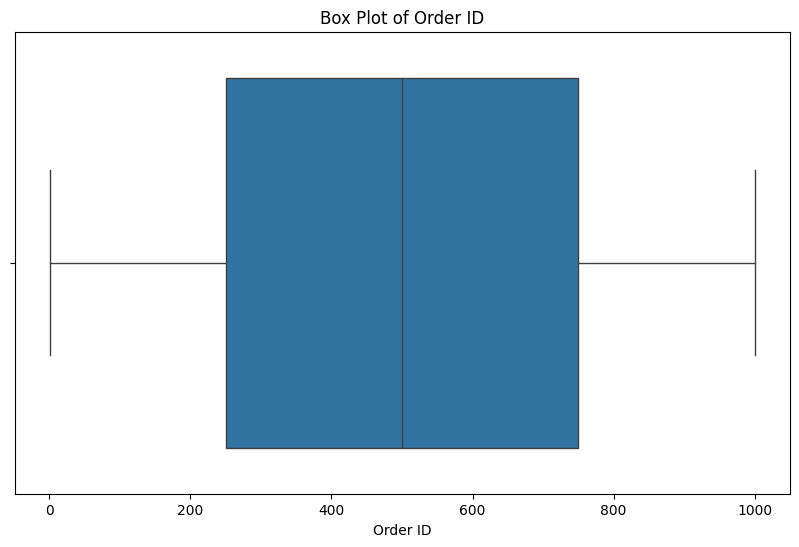

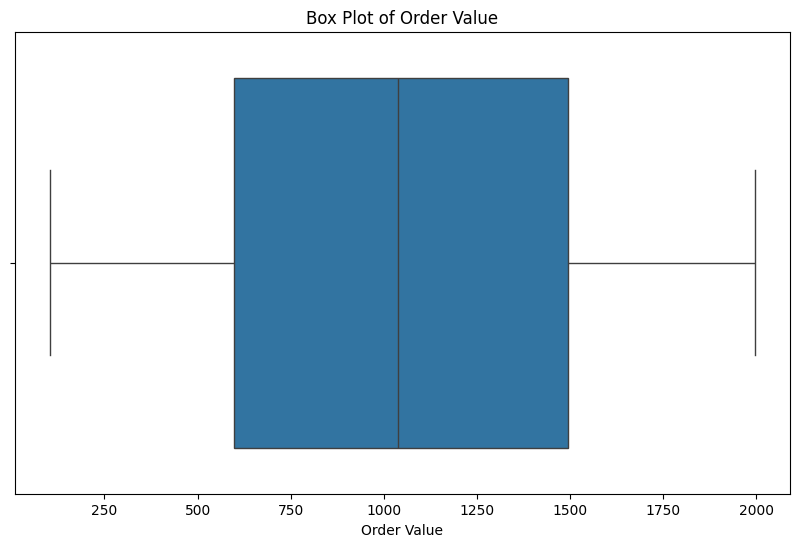

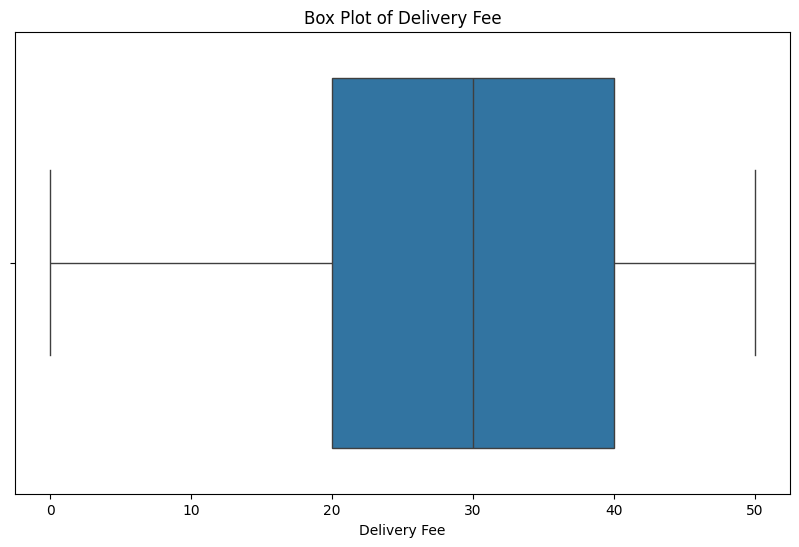

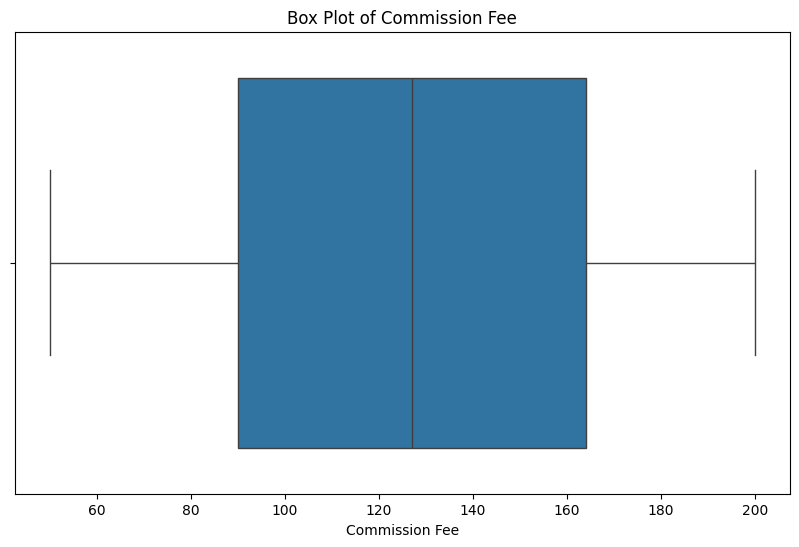

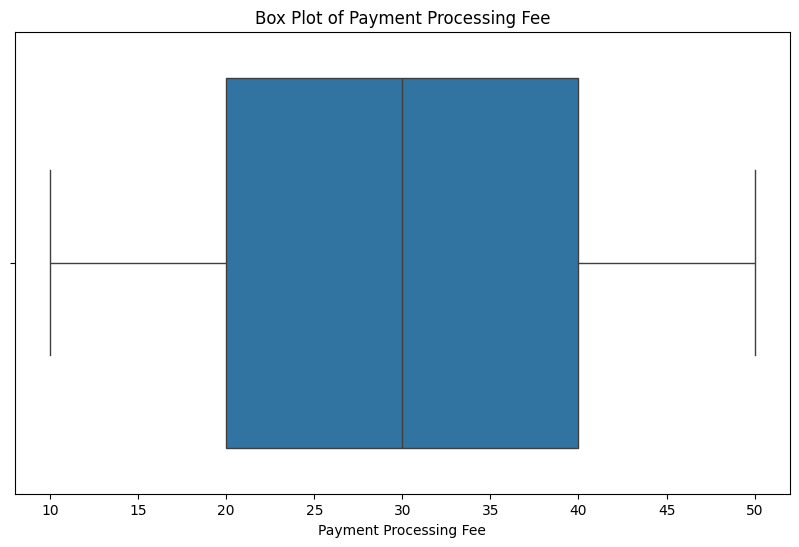

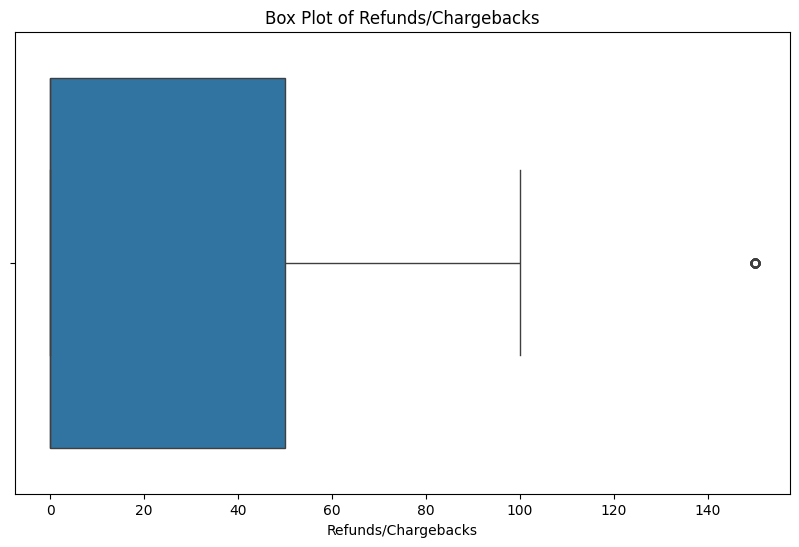

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [11]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [12]:
condition = (
    (df[numeric_features] < (Q1 - 1.5 * IQR)) |
    (df[numeric_features] > (Q3 - 1.5 * IQR))
).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]

categorical_features = df.select_dtypes(include=['object']).columns

df = pd.concat(
    [df_filtered_numeric, df.loc[condition, categorical_features]],
    axis=1
)

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_9304\1868069527.py:8: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = df.select_dtypes(include=['object']).columns


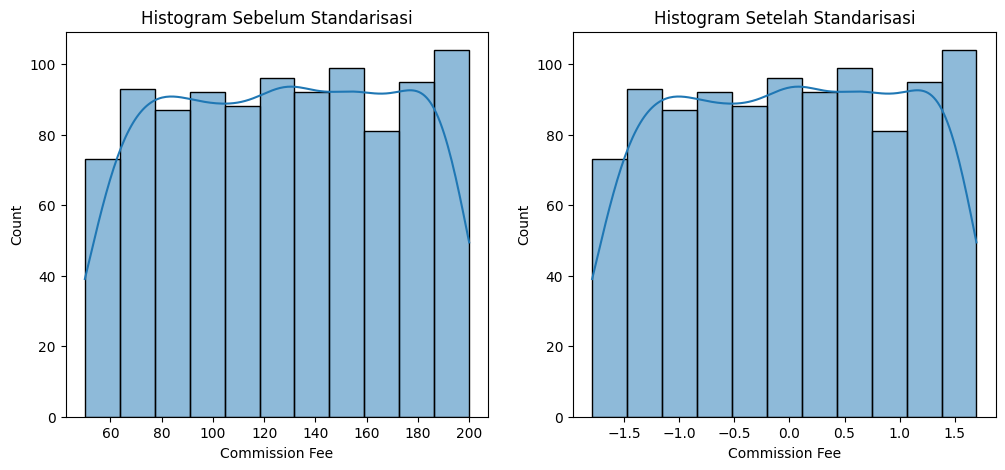

In [13]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(food[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standarisasi")
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standarisasi")
plt.show()

In [14]:
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])


Baris duplikat:
Empty DataFrame
Columns: [Order ID, Order Value, Delivery Fee, Commission Fee, Payment Processing Fee, Refunds/Chargebacks, Customer ID, Restaurant ID, Order Date and Time, Delivery Date and Time, Payment Method, Discounts and Offers]
Index: []


In [15]:
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
     Order ID  Order Value  Delivery Fee  Commission Fee  \
0   -1.730320     1.620530     -1.688516        0.534588   
1   -1.726856    -0.128072      0.671394        1.649764   
2   -1.723391    -0.220401      0.081417        1.580066   
3   -1.719927     0.770724      1.261372        0.441656   
4   -1.716463     1.767503      0.081417        0.069931   
..        ...          ...           ...             ...   
995  1.716463    -0.431439     -1.688516        0.883080   
996  1.719927     1.079745      1.261372       -0.394726   
997  1.723391    -0.943960     -0.508561       -1.463437   
998  1.726856     0.678395     -1.688516        1.672997   
999  1.730320     1.136273     -0.508561        1.231573   

     Payment Processing Fee  Refunds/Chargebacks Customer ID Restaurant ID  \
0                  1.477281            -0.570686       C8270         R2924   
1                 -0.587884            -0.570686       C1860         R2054   
2      

In [16]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

C:\Users\Ahmad Raja\AppData\Local\Temp\ipykernel_9304\2319133481.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  category_features = df.select_dtypes(include=['object']).columns


,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Payment Method,Discounts and Offers
0,C8270,R2924,2024-02-01 01:11:52,2024-02-01 02:39:52,Credit Card,5% on App
1,C1860,R2054,2024-02-02 22:11:04,2024-02-02 22:46:04,Digital Wallet,10%
2,C6390,R2870,2024-01-31 05:54:35,2024-01-31 06:52:35,Cash on Delivery,15% New User
3,C6191,R2642,2024-01-16 22:52:49,2024-01-16 23:38:49,Cash on Delivery,10%
4,C6734,R2799,2024-01-29 01:19:30,2024-01-29 02:48:30,Cash on Delivery,50 off Promo
...,...,...,...,...,...,...
995,C6232,R2129,2024-01-14 05:57:00,2024-01-14 06:39:00,Digital Wallet,5% on App
996,C6797,R2742,2024-01-28 08:50:43,2024-01-28 10:10:43,Cash on Delivery,10%
997,C5926,R2837,2024-01-21 09:43:19,2024-01-21 10:44:19,Cash on Delivery,10%
998,C7016,R2144,2024-01-30 22:23:38,2024-01-31 00:07:38,Cash on Delivery,15% New User


In [17]:
df_one_hot = pd.get_dummies(df, columns=category_features)
df_one_hot

,Order ID,Order Value,Delivery Fee,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Customer ID_C1004,Customer ID_C1005,Customer ID_C1009,Customer ID_C1055,...,Delivery Date and Time_2024-02-07 22:55:22,Delivery Date and Time_2024-02-07 23:53:39,Delivery Date and Time_2024-02-08 01:45:12,Payment Method_Cash on Delivery,Payment Method_Credit Card,Payment Method_Digital Wallet,Discounts and Offers_10%,Discounts and Offers_15% New User,Discounts and Offers_5% on App,Discounts and Offers_50 off Promo
0,-1.730320,1.620530,-1.688516,0.534588,1.477281,-0.570686,False,False,False,False,...,False,False,False,False,True,False,False,False,True,False
1,-1.726856,-0.128072,0.671394,1.649764,-0.587884,-0.570686,False,False,False,False,...,False,False,False,False,False,True,True,False,False,False
2,-1.723391,-0.220401,0.081417,1.580066,1.305184,-0.570686,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False
3,-1.719927,0.770724,1.261372,0.441656,-0.243689,-0.570686,False,False,False,False,...,False,False,False,True,False,False,True,False,False,False
4,-1.716463,1.767503,0.081417,0.069931,1.735427,-0.570686,False,False,False,False,...,False,False,False,True,False,False,False,False,False,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,1.716463,-0.431439,-1.688516,0.883080,1.477281,0.437593,False,False,False,False,...,False,False,False,False,False,True,False,False,True,False
996,1.719927,1.079745,1.261372,-0.394726,1.047038,-0.570686,False,False,False,False,...,False,False,False,True,False,False,True,False,False,False
997,1.723391,-0.943960,-0.508561,-1.463437,0.100505,-0.570686,False,False,False,False,...,False,False,False,True,False,False,True,False,False,False
998,1.726856,0.678395,-1.688516,1.672997,0.358650,-0.570686,False,False,False,False,...,False,False,False,True,False,False,False,True,False,False


In [18]:
from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()
df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

df_lencoder

,Order ID,Order Value,Delivery Fee,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Payment Method,Discounts and Offers
0,-1.730320,1.620530,-1.688516,0.534588,1.477281,-0.570686,771,566,806,806,1,2
1,-1.726856,-0.128072,0.671394,1.649764,-0.587884,-0.570686,82,34,863,861,2,0
2,-1.723391,-0.220401,0.081417,1.580066,1.305184,-0.570686,550,523,777,777,0,1
3,-1.719927,0.770724,1.261372,0.441656,-0.243689,-0.570686,528,384,410,410,0,0
4,-1.716463,1.767503,0.081417,0.069931,1.735427,-0.570686,591,480,726,726,0,3
...,...,...,...,...,...,...,...,...,...,...,...,...
995,1.716463,-0.431439,-1.688516,0.883080,1.477281,0.437593,530,79,327,326,2,2
996,1.719927,1.079745,1.261372,-0.394726,1.047038,-0.570686,600,446,710,710,0,0
997,1.723391,-0.943960,-0.508561,-1.463437,0.100505,-0.570686,495,505,532,532,0,0
998,1.726856,0.678395,-1.688516,1.672997,0.358650,-0.570686,628,87,772,772,0,1


In [19]:
#Praktek EDA dan ExDA
df_lencoder.head()

,Order ID,Order Value,Delivery Fee,Commission Fee,Payment Processing Fee,Refunds/Chargebacks,Customer ID,Restaurant ID,Order Date and Time,Delivery Date and Time,Payment Method,Discounts and Offers
0,-1.730320,1.620530,-1.688516,0.534588,1.477281,-0.570686,771,566,806,806,1,2
1,-1.726856,-0.128072,0.671394,1.649764,-0.587884,-0.570686,82,34,863,861,2,0
2,-1.723391,-0.220401,0.081417,1.580066,1.305184,-0.570686,550,523,777,777,0,1
3,-1.719927,0.770724,1.261372,0.441656,-0.243689,-0.570686,528,384,410,410,0,0
4,-1.716463,1.767503,0.081417,0.069931,1.735427,-0.570686,591,480,726,726,0,3


In [20]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) *100

missing_data = pd.DataFrame({
    'Missing_Values': missing_values,
    'Percentage': missing_percentage 
}).sort_values(by='Missing_Values', ascending=False)

missing_data[missing_data['Missing_Values']> 0]

,Missing_Values,Percentage


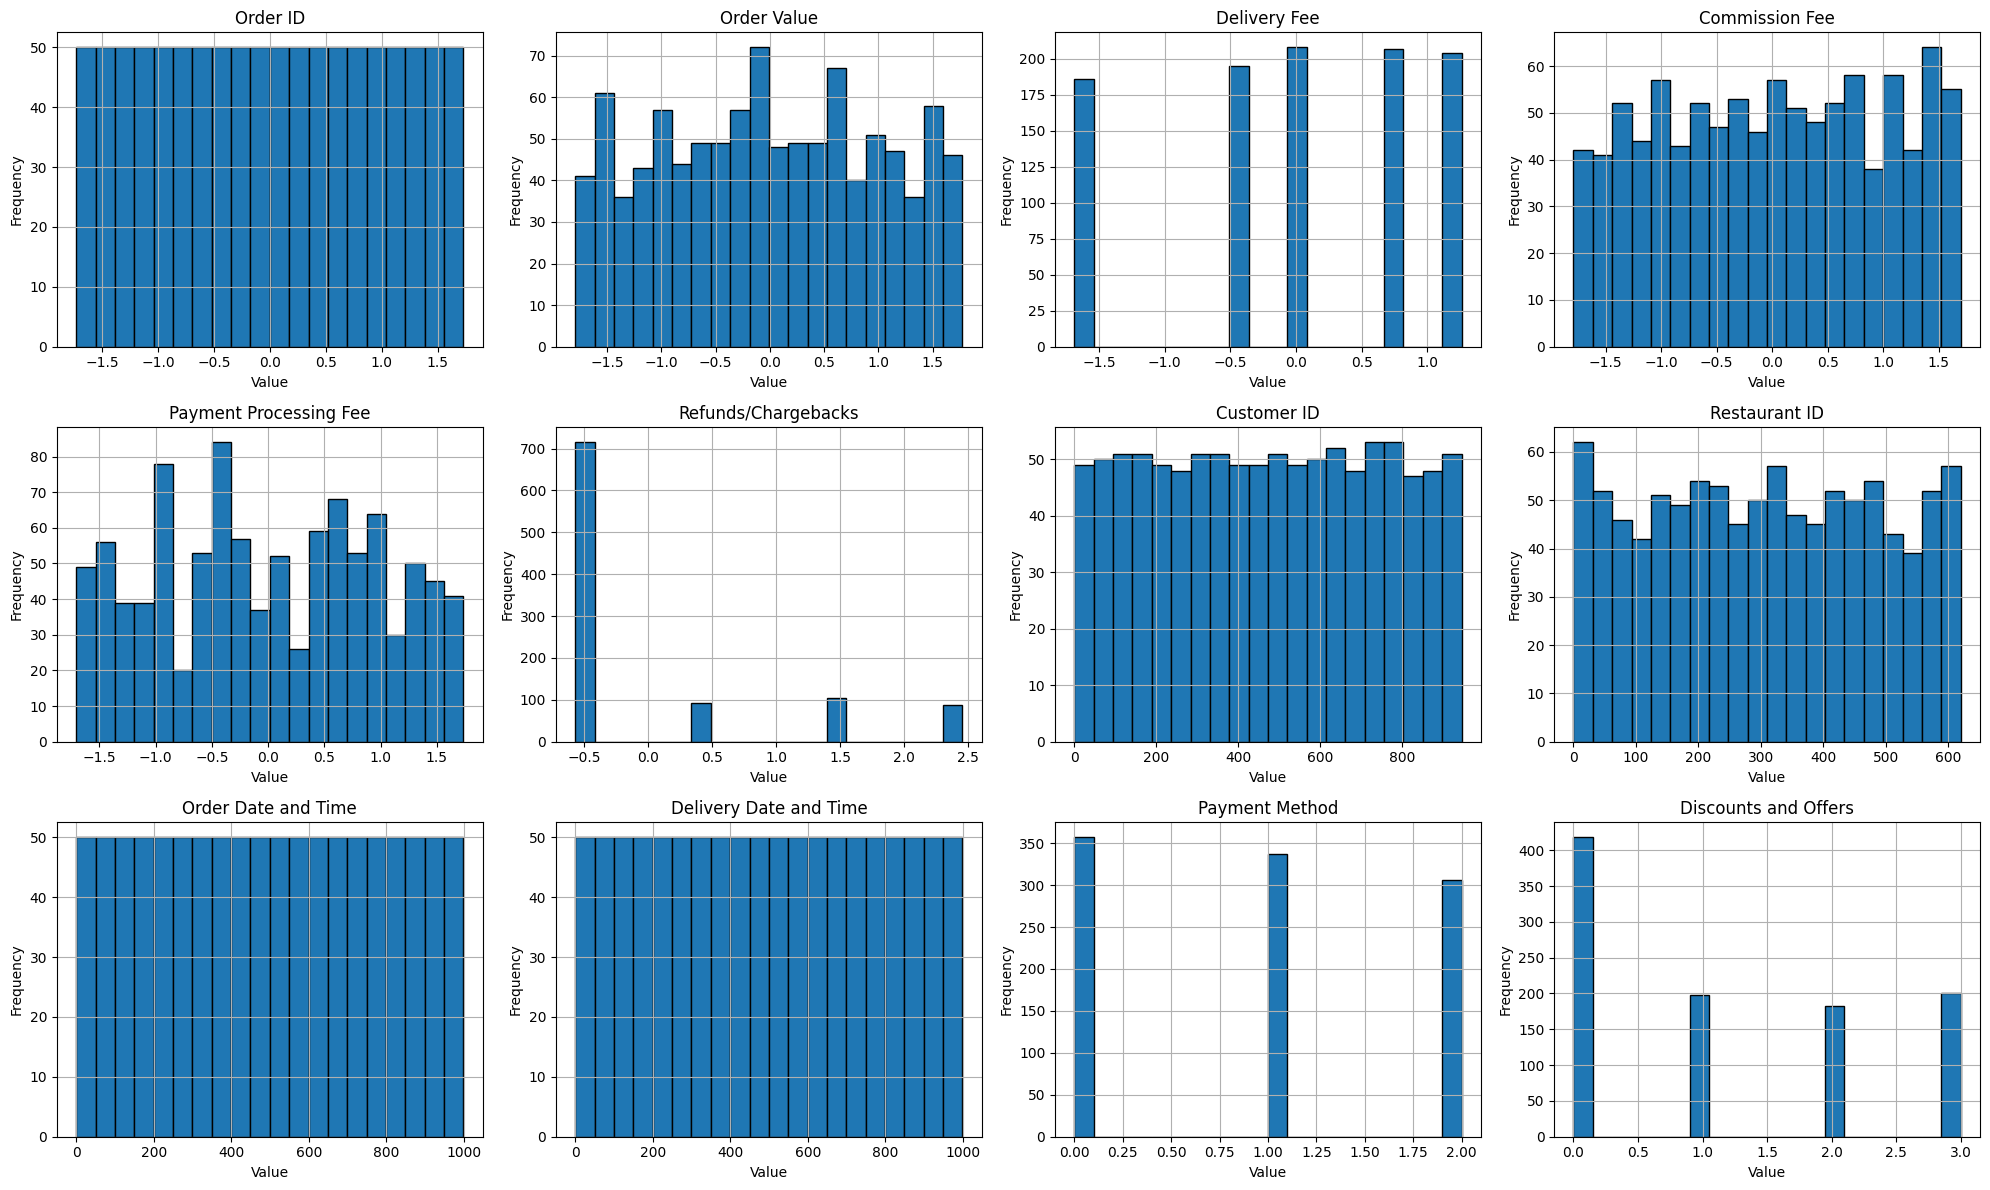

In [21]:
num_vars = df_lencoder.shape[1]

n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, n_rows * 4))
axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(ax=axes[i], bins=20, edgecolor='black')
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')


for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])


plt.tight_layout()
plt.show()


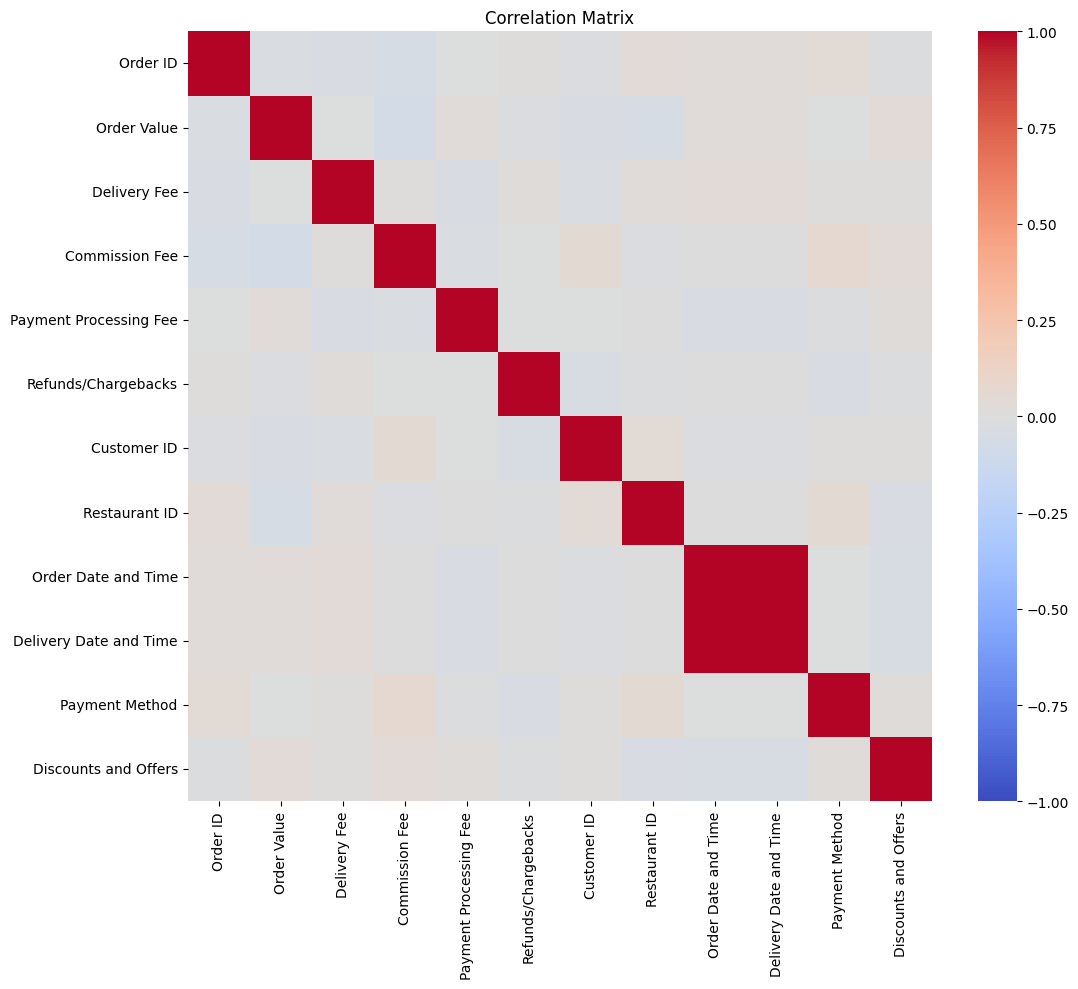

In [22]:
# Visualisasi korelasi antar variabel numerik
plt.figure(figsize=(12, 10))
correlation_matrix = df_lencoder.corr()

sns.heatmap(correlation_matrix, annot=False, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
plt.show()


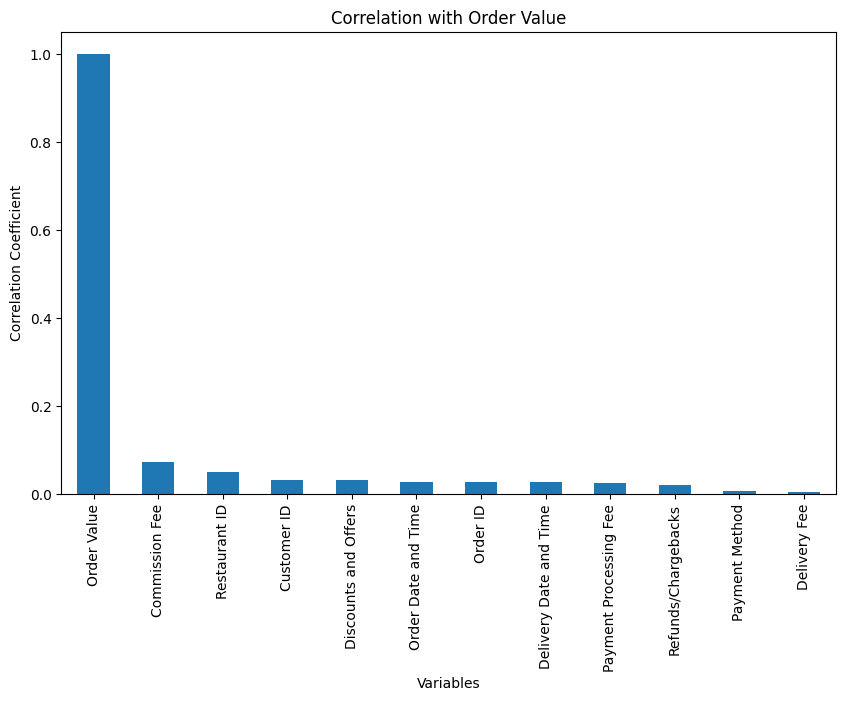

In [27]:
 # Menghitung korelasi antara variabel target dan semua variabel lainnya
target_corr = df_lencoder.corr()['Order Value']

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with Order Value')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

In [28]:
import sklearn

In [30]:
# Memisahkan fitur (X) dan target (y)
X = df_lencoder.drop(columns=['Order Value'])
y = df_lencoder['Order Value'] 

In [32]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [33]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  1000
Jumlah data latih:  800
Jumlah data test:  200


In [35]:
# Melatih model 1 dengan algoritma Least Angle Regression
from sklearn import linear_model
lars = linear_model.Lars(n_nonzero_coefs=1).fit(x_train, y_train)

# Melatih model 2 dengan algoritma Linear Regression
from sklearn.linear_model import LinearRegression
LR = LinearRegression().fit(x_train, y_train)

# Melatih model 3 dengan algoritma Gradient Boosting Regressor
from sklearn.ensemble import GradientBoostingRegressor
GBR = GradientBoostingRegressor(random_state=184)
GBR.fit(x_train, y_train)

,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.1
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",100
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",1.0
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",3
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft 

In [36]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluasi pada model LARS
pred_lars = lars.predict(x_test)
mae_lars = mean_absolute_error(y_test, pred_lars)
mse_lars = mean_squared_error(y_test, pred_lars)
r2_lars = r2_score(y_test, pred_lars)

# Membuat dictionary untuk menyimpan hasil evaluasi
data = {
     'MAE': [mae_lars],
     'MSE': [mse_lars],
     'R2': [r2_lars]
    }

# Konversi dictionary menjadi DataFrame
df_results = pd.DataFrame(data, index=['Lars'])
df_results

,MAE,MSE,R2
Lars,0.808385,0.932371,-0.02588


In [37]:
# Evaluasi pada model Linear Regression
pred_LR = LR.predict(x_test)
mae_LR = mean_absolute_error(y_test, pred_LR)
mse_LR = mean_squared_error(y_test, pred_LR)
r2_LR = r2_score(y_test, pred_LR)

# Menambahkan hasil evaluasi LR ke DataFrame
df_results.loc['Linear Regression'] = [mae_LR, mse_LR, r2_LR]
df_results


,MAE,MSE,R2
Lars,0.808385,0.932371,-0.025880
Linear Regression,0.814426,0.956544,-0.052477


In [38]:
# Evaluasi pada model Gradient Boosting Regressor
pred_GBR = GBR.predict(x_test)
mae_GBR = mean_absolute_error(y_test, pred_GBR)
mse_GBR = mean_squared_error(y_test, pred_GBR)
r2_GBR = r2_score(y_test, pred_GBR)

# Menambahkan hasil evaluasi GBR ke DataFrame
df_results.loc['GradientBoostingRegressor'] = [mae_GBR, mse_GBR, r2_GBR]
df_results

,MAE,MSE,R2
Lars,0.808385,0.932371,-0.025880
Linear Regression,0.814426,0.956544,-0.052477
GradientBoostingRegressor,0.837278,0.969031,-0.066217


In [39]:
import joblib
# Menyimpan model ke dalam file
joblib.dump(GBR, 'gbr_model.joblib')

['gbr_model.joblib']

In [40]:
import pickle
# Menyimpan model ke dalam file
with open('gbr_model.pkl', 'wb') as file:
        pickle.dump(GBR, file)